In [55]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

project_root = Path.cwd()
if not (project_root / "network_creation").exists():
    project_root = project_root.parent
sys.path.insert(0, str(project_root))

from network_creation.core.graph import create_empty_graph, create_erdos_renyi_graph
from network_creation.core.observability import ObservationSampling
from network_creation.data.choi_2020 import (
    build_replay_simulator,
    list_choi_2020_configs,
    load_choi_2020_normalized_data,
)
from network_creation.observers.state_history_observer import StateHistoryObserver
from network_creation.plotting.plot_network import draw_network
from network_creation.stats.topology_welfare import get_ER_normalized_welfare
from notebooks.utils.save_graph_tikz import save_graph_tikz

In [56]:
def make_periphery_sponsored_star(n):
    graph = create_empty_graph(n)
    graph.add_edges((node_id, 0) for node_id in range(1, n))
    return graph


def make_empty_layout(n, seed):
    if n <= 0:
        return {}

    rng = np.random.default_rng(seed)
    n_cols = int(np.ceil(np.sqrt(n)))
    n_rows = int(np.ceil(n / n_cols))
    points = np.array(
        [
            (x, y)
            for y in np.linspace(0.12, 0.88, n_rows)[::-1]
            for x in np.linspace(0.12, 0.88, n_cols)
        ],
        dtype=float,
    )[:n]
    points += rng.normal(0.0, 0.015, points.shape)
    points = np.clip(points, 0.06, 0.94)
    return {node_id: tuple(point) for node_id, point in enumerate(points)}


def welfare_maximizing_er_p(n):
    p_grid = np.linspace(0.0, 1.0, 1000)
    welfare = [
        get_ER_normalized_welfare(
            n=n,
            benefit_to_cost_ratio=10 / (2 * n),
            distance_discount=0.9,
            p_directed=p,
        )
        for p in p_grid
    ]
    return float(p_grid[int(np.argmax(welfare))])


def make_last_choi_graph(n, random_seed):
    all_configs = list_choi_2020_configs(project_root / "data/choi_2020/raw")
    configs = [config for config in all_configs if config.group_size == n]
    if not configs:
        available = sorted({config.group_size for config in all_configs})
        raise ValueError(f"Choi 2020 group sizes are {available}, not {n}.")

    config = configs[np.random.default_rng(random_seed).integers(len(configs))]
    max_steps = load_choi_2020_normalized_data(config).max_step
    observer = StateHistoryObserver(ObservationSampling.terminal(), keep_runs=False)
    simulator = build_replay_simulator(config, observers=(observer,), max_steps=max_steps)
    simulator.run(n_episodes=1, reset_observers=False)
    return observer.graphs[-1]


In [57]:
network_size = 10
random_seed = 12

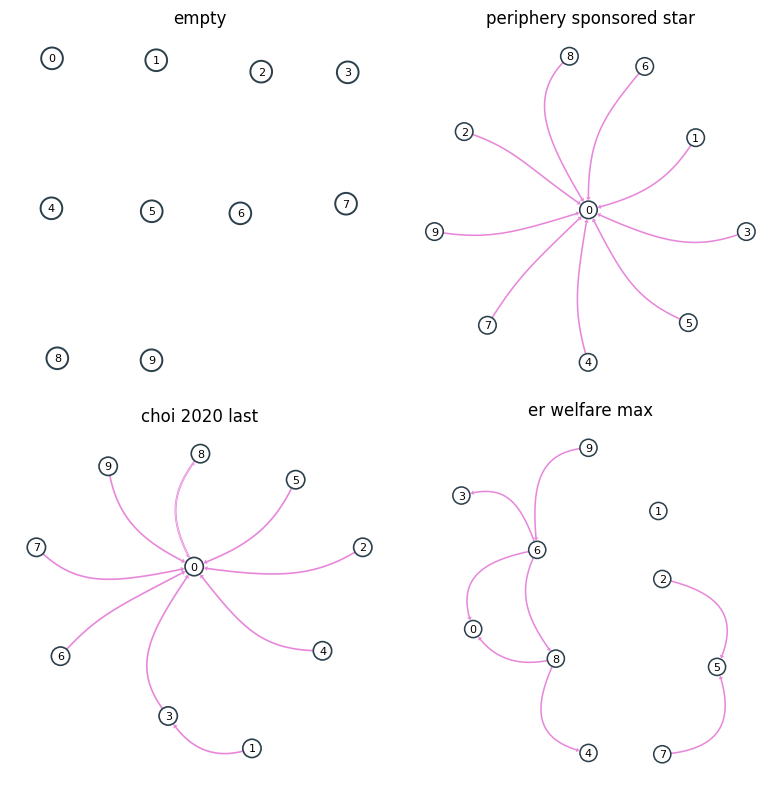

['choi_2020_last.tex',
 'empty.tex',
 'er_welfare_max.tex',
 'periphery_sponsored_star.tex']

In [58]:
output_dir = project_root / "notebooks/example_graphs"
output_dir.mkdir(parents=True, exist_ok=True)

best_er_p = welfare_maximizing_er_p(network_size)
graphs = {
    "empty": create_empty_graph(network_size),
    "periphery_sponsored_star": make_periphery_sponsored_star(network_size),
    "choi_2020_last": make_last_choi_graph(network_size, random_seed),
    "er_welfare_max": create_erdos_renyi_graph(network_size, best_er_p, random_seed),
}

np.random.seed(random_seed)
figure, axes = plt.subplots(2, 2, figsize=(8, 8))

for axis, (name, graph) in zip(axes.ravel(), graphs.items(), strict=True):
    graph_nx = graph.to_networkx(vertex_attr_hashable="name")
    layout = make_empty_layout(network_size, random_seed) if name == "empty" else "spring"
    drawn_graph = draw_network(graph_nx, axis, node_layout=layout)
    axis.set_title(name.replace("_", " "))
    axis.set_axis_off()
    save_graph_tikz(
        drawn_graph,
        scale=3.0,
        filename=output_dir / f"{name}.tex",
        edge_width=0.005,
        node_color="#ffffff",
        edge_color="#000000",
        node_border_color="#000000",
        node_border_width=0.005,
        arrow_length_factor=4.0,
        arrow_width_factor=6.0,
        arrows=True,
    )

figure.tight_layout()
plt.show()
sorted(path.name for path in output_dir.glob("*.tex"))
